# Análise de XPS: survey, C 1s, O 1s e Si 2p

Este notebook segue a **Parte 5 (Deconvolução de picos)** do notebook *ATP-201 – Regressão não-linear*.

**Como usar:** coloque os quatro arquivos `.avg` na mesma pasta deste notebook e rode as células em ordem.

**O que muda em relação ao notebook da aula:**

1. Os dados vêm em arquivos `.avg` (texto), e não em Excel. Por isso existe uma função própria para lê-los.
2. Os picos são **Voigt** (`VoigtModel`), e não Lorentzianos.
3. As sigmoides têm amplitude mínima zero (`min=0`).
4. Quando há mais de um pico, o `gamma` de todos é igual ao do primeiro.
5. O ajuste usa `method="least_squares"`.

## Importações

In [1]:
import numpy as np
import pandas as pd

from lmfit.models import ConstantModel, StepModel, VoigtModel
from matplotlib import pyplot as plt

## Nomes dos arquivos

Se os seus arquivos tiverem outro nome (por exemplo, `C1s Scan.avg` com espaço), troque aqui.

In [2]:
ARQUIVO_SURVEY = "dados_xps/XPS Survey.avg"
ARQUIVO_C1S = "dados_xps/C1s Scan.avg"
ARQUIVO_O1S = "dados_xps/O1s Scan.avg"
ARQUIVO_SI2P = "dados_xps/Si2p Scan.avg"

## Funções de suporte

### 1. Ler um arquivo `.avg`

Esta função substitui o `pd.read_excel` do notebook da aula. Ela percorre o arquivo linha por linha:

- `open(...)` e `readlines()`: abrem o arquivo e guardam cada linha como um texto em uma lista.
- `linha.startswith("...")`: testa se a linha começa com um certo texto. É assim que achamos as informações úteis.
- Linha `DS_SOPROPID_ENERGY`: tem a energia do raio X (1486,68 eV). `split("=")[-1]` pega o que vem depois do último `=`, e `float(...)` transforma esse texto em número.
- Linha `$SPACEAXES`: a linha **seguinte** a ela (`linhas[i + 1]`) tem o início, o passo e o número de pontos do eixo de energia.
- Linhas `LIST@`: têm as contagens, 4 por linha. `split("=")[1]` joga fora o pedaço `LIST@ 12`, que é só a posição do primeiro valor, e `split(",")` separa os 4 números.
- `np.arange(n_pontos)` cria `0, 1, 2, ...`. Multiplicando pelo passo e somando o início, montamos o eixo de **energia cinética**.
- **Energia de ligação = energia do raio X − energia cinética.**
- No fim, guardamos tudo em um `DataFrame` com as colunas `eV` e `Contagens`, como no notebook da aula.

In [3]:
def le_arquivo_avg(caminho):
    """Lê um arquivo .avg exportado pelo Avantage.

    Args:
      caminho: string
        Nome (ou caminho) do arquivo .avg.

    Return:
      DataFrame com as colunas `eV` (energia de ligação) e `Contagens`.
    """

    with open(caminho, encoding="latin-1") as arquivo:
        linhas = arquivo.readlines()

    contagens = []

    for i, linha in enumerate(linhas):
        if linha.startswith("DS_SOPROPID_ENERGY"):
            energia_foton = float(linha.split("=")[-1])

        elif linha.startswith("$SPACEAXES"):
            numeros = linhas[i + 1].split("=")[1].split(",")
            inicio = float(numeros[0])
            passo = float(numeros[1])
            n_pontos = int(numeros[2])

        elif linha.startswith("LIST@"):
            valores = linha.split("=")[1].split(",")
            contagens += [float(v) for v in valores if v.strip()]

    energia_cinetica = inicio + passo * np.arange(n_pontos)
    energia_ligacao = energia_foton - energia_cinetica

    df = pd.DataFrame({"eV": energia_ligacao, "Contagens": contagens})

    return df

### 2. Montar o modelo (picos Voigt + sigmoides + constante)

É a mesma receita do notebook da aula (cada pico com a sua sigmoide, mais uma constante), dentro de um `for` para não repetir o código para cada pico.

- `palpites` é uma lista em que cada item é `(centro, mínimo, máximo, área)` de um pico.
- `prefix="p1_"`, `"p2_"`...: dá nome a cada pedaço do modelo. É isso que permite desenhar cada pico separado depois.
- `modelo = modelo + ...`: soma os pedaços, como o `modelo_composto` do notebook.
- `params.update(...)`: junta os parâmetros de cada pedaço em um objeto só.
- `.set(value=..., min=..., max=...)`: palpite inicial e limites de cada parâmetro.
- **Na Voigt, o palpite é a área (`amplitude`), e não a altura.**
- `gamma` controla o quanto o pico tem de "cara de Lorentziana". O do primeiro pico é livre (`vary=True`), e os outros copiam ele (`expr="p1_gamma"`). Com todos livres, o ajuste do C 1s não converge.
- A sigmoide usa o centro e a largura do seu pico (`expr=...`), como no notebook. A diferença é o `min=0` na amplitude: o degrau só pode **subir** para o lado de maior energia de ligação. Sem isso, as sigmoides de picos vizinhos se cancelam e um pico some.

In [4]:
def monta_modelo(palpites, palpite_constante):
    """Cria o modelo composto e os parâmetros com os palpites iniciais.

    Args:
      palpites: lista de tuplas (centro, mínimo, máximo, área), uma por pico.
      palpite_constante: float, palpite da linha de base constante.

    Return:
      modelo_composto e params.
    """

    modelo_constante = ConstantModel(prefix="const_")
    params = modelo_constante.make_params(c=palpite_constante)
    modelo_composto = modelo_constante

    for i, (centro, minimo, maximo, area) in enumerate(palpites, start=1):
        pico = f"p{i}_"
        sigmoid = f"sigmoid{i}_"

        modelo_pico = VoigtModel(prefix=pico)
        modelo_sigmoid = StepModel(
            prefix=sigmoid, form="logistic", independent_vars=["x"]
        )

        modelo_composto = modelo_composto + modelo_pico + modelo_sigmoid
        params.update(modelo_pico.make_params())
        params.update(modelo_sigmoid.make_params())

        # palpites do pico
        params[pico + "center"].set(value=centro, min=minimo, max=maximo)
        params[pico + "sigma"].set(value=0.5, min=0.05, max=2)
        params[pico + "amplitude"].set(value=area, min=0)

        if i == 1:
            params["p1_gamma"].set(vary=True, value=0.2, min=0.01, max=2)
        else:
            params[pico + "gamma"].set(expr="p1_gamma")

        # sigmoide presa ao seu pico
        params[sigmoid + "amplitude"].set(value=0.02 * area, min=0)
        params[sigmoid + "center"].set(vary=False, expr=pico + "center")
        params[sigmoid + "sigma"].set(vary=False, expr=pico + "sigma")

    return modelo_composto, params

### 3. Gráfico das componentes

Parecido com a seção *A contribuição de cada componente* do notebook, com uma diferença: em XPS, cada pico costuma ser desenhado **em cima da linha de base**, e não a partir do zero.

- `eval_components(x=...)`: devolve a curva de cada pedaço do modelo, com o prefixo como nome.
- `linha_base`: soma da constante com todas as sigmoides. `np.ones(len(dados_x))` transforma a constante em uma linha do tamanho de x.
- `fill_between(x, y_baixo, y_cima)`: pinta a área entre duas curvas, ou seja, a área de cada pico.
- `invert_xaxis()`: inverte o eixo x. Em XPS, o costume é a energia de ligação **diminuir** para a direita.
- A função recebe o `eixo` onde vai desenhar. Assim dá para usá-la tanto em um gráfico sozinho quanto na figura com 4 painéis do final.

In [5]:
def plota_componentes(df, resultado_fit, nomes_picos, titulo, eixo):
    """Desenha dados, picos, linha de base e ajuste total em `eixo`."""

    dados_x = df["eV"].values
    dados_y = df["Contagens"].values

    componentes = resultado_fit.eval_components(x=dados_x)

    linha_base = componentes["const_"] * np.ones(len(dados_x))
    for i in range(1, len(nomes_picos) + 1):
        linha_base = linha_base + componentes[f"sigmoid{i}_"]

    eixo.plot(dados_x, dados_y, "o", markersize=3, color="gray", label="Dados")

    for i, nome in enumerate(nomes_picos, start=1):
        topo_do_pico = linha_base + componentes[f"p{i}_"]
        eixo.fill_between(dados_x, linha_base, topo_do_pico, alpha=0.4, label=nome)

    eixo.plot(dados_x, linha_base, "--", color="dimgray", label="Linha de base")
    eixo.plot(dados_x, resultado_fit.best_fit, color="black", label="Ajuste total")

    eixo.invert_xaxis()
    eixo.set(xlabel="Energia de ligação (eV)", ylabel="Contagens", title=titulo)
    eixo.legend()

### 4. Porcentagem de cada pico

A área de cada pico (`amplitude`) dividida pela soma das áreas dá a fração de cada tipo de ligação.

In [6]:
def mostra_porcentagens(resultado_fit, nomes_picos):
    """Imprime centro, largura (FWHM) e % de área de cada pico."""

    areas = [resultado_fit.params[f"p{i}_amplitude"].value
             for i in range(1, len(nomes_picos) + 1)]
    total = sum(areas)

    for i, nome in enumerate(nomes_picos, start=1):
        centro = resultado_fit.params[f"p{i}_center"].value
        fwhm = resultado_fit.params[f"p{i}_fwhm"].value
        print(f"{nome:12s} centro = {centro:.2f} eV   FWHM = {fwhm:.2f} eV   "
              f"área = {100 * areas[i - 1] / total:.0f} %")

## Survey

O survey não é ajustado, apenas plotado e identificado.

- `df.plot("eV", "Contagens", ...)`: igual ao notebook. Ele devolve o eixo do gráfico, que guardamos em `eixo`.
- `IDENTIFICACAO`: dicionário com o nome de cada pico e a sua energia de ligação.
- `np.argmin(np.abs(...))`: acha o ponto do espectro mais perto daquela energia, para escrever o nome logo acima dele.
- `eixo.annotate(texto, (x, y), ...)`: escreve um texto no gráfico. `xytext=(0, 5)` com `textcoords="offset points"` sobe o texto 5 pontos para ele não ficar em cima da linha, e `rotation=90` escreve na vertical, para nomes de picos próximos (como Si 2s e Si 2p) não se sobreporem.
- `eixo.margins(y=0.15)`: deixa uma folga de 15% em cima, para o nome do O 1s caber dentro do gráfico.

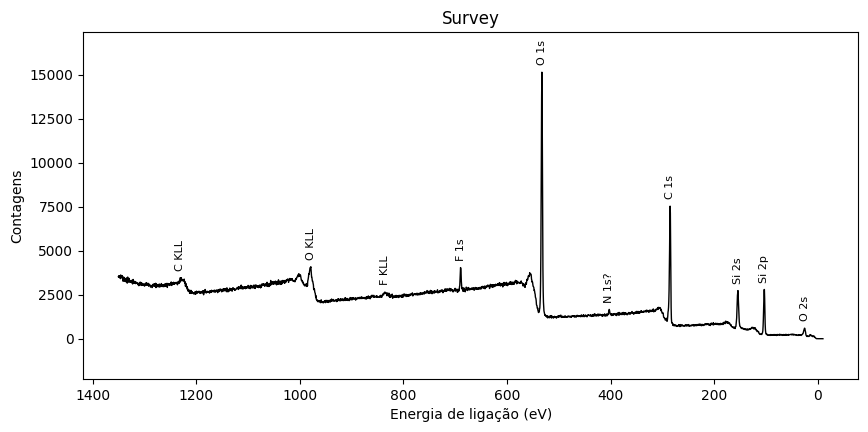

In [7]:
df_survey = le_arquivo_avg(ARQUIVO_SURVEY)

IDENTIFICACAO = {
    "O 1s": 532.6, "C 1s": 285.1, "F 1s": 689.6, "Si 2p": 103.6,
    "Si 2s": 154.1, "O 2s": 25.6, "O KLL": 978.6, "F KLL": 835.6,
    "C KLL": 1230.6, "N 1s?": 402.6,
}

eixo = df_survey.plot("eV", "Contagens", color="black", lw=1, legend=False, figsize=(10, 4.5))

for nome, energia in IDENTIFICACAO.items():
    i = np.argmin(np.abs(df_survey["eV"].values - energia))
    eixo.annotate(
        nome,
        (df_survey["eV"].values[i], df_survey["Contagens"].values[i]),
        xytext=(0, 5), textcoords="offset points",
        rotation=90, ha="center", va="bottom", fontsize=8,
    )

eixo.margins(y=0.15)
eixo.invert_xaxis()
eixo.set(xlabel="Energia de ligação (eV)", ylabel="Contagens", title="Survey");

## C 1s

4 picos: C–C/C–H (carbono de contaminação, usado como referência em 284,8 eV), C–O, O–C=O e CF₂.

### Carregando e cortando os dados

Mesma lógica do notebook (`logic = df["eV"] <= 535`), mas cortando dos dois lados: ficamos só com a região entre 281 e 296 eV.

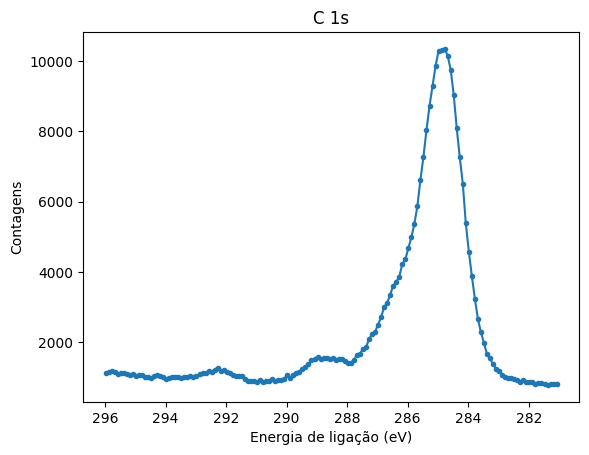

In [8]:
df_c1s = le_arquivo_avg(ARQUIVO_C1S)

logic = (df_c1s["eV"] >= 281) & (df_c1s["eV"] <= 296)
df_c1s = df_c1s.loc[logic]

eixo = df_c1s.plot("eV", "Contagens", marker="o", markersize=3, legend=False)
eixo.invert_xaxis()
eixo.set(xlabel="Energia de ligação (eV)", ylabel="Contagens", title="C 1s");

### Palpites, modelo e ajuste

- `PALPITES_...`: um item por pico, no formato `(centro, mínimo, máximo, área)`.
- `monta_modelo(...)`: monta o modelo composto e os parâmetros (função lá de cima).
- `.fit(...)` e `fit_report()`: iguais ao notebook, com um argumento a mais: `method="least_squares"`. É outro algoritmo de ajuste do lmfit, que lida melhor com os limites `min`/`max`. Com o algoritmo padrão, quando uma sigmoide encosta no limite zero, o lmfit não consegue calcular as incertezas (os `+/-` do relatório).
- `resultado_fit.plot(...)`: gráfico pronto do lmfit, com os resíduos em cima e o ajuste embaixo. O `title` evita que ele use como título o nome enorme do modelo. `plt.gca()` pega o último gráfico desenhado para inverter o eixo x (o de resíduos acompanha).

In [9]:
PALPITES_C1S = [
    (284.8, 284.2, 285.3, 15000),  # C–C / C–H
    (286.3, 285.7, 287.0, 5000),   # C–O
    (288.8, 288.0, 289.5, 1000),   # O–C=O
    (292.3, 291.5, 293.0, 300),    # CF2
]

modelo_c1s, params_c1s = monta_modelo(PALPITES_C1S, palpite_constante=800)

dados_x = df_c1s["eV"].values
dados_y = df_c1s["Contagens"].values

resultado_c1s = modelo_c1s.fit(dados_y, params_c1s, x=dados_x, method="least_squares")

print(resultado_c1s.fit_report())

[[Model]]
    ((((((((Model(constant, prefix='const_') + Model(voigt, prefix='p1_')) + Model(step, prefix='sigmoid1_', form='logistic')) + Model(voigt, prefix='p2_')) + Model(step, prefix='sigmoid2_', form='logistic')) + Model(voigt, prefix='p3_')) + Model(step, prefix='sigmoid3_', form='logistic')) + Model(voigt, prefix='p4_')) + Model(step, prefix='sigmoid4_', form='logistic'))
[[Fit Statistics]]
    # fitting method   = least_squares
    # function evals   = 285
    # data points      = 150
    # variables        = 18
    chi-square         = 345873.556
    reduced chi-square = 2620.25422
    Akaike info crit   = 1197.47899
    Bayesian info crit = 1251.67042
    R-squared          = 0.99960951
[[Variables]]
    const_c:             724.314573 +/- 76.2742083 (10.53%) (init = 800)
    p1_amplitude:        15486.5800 +/- 4514.84016 (29.15%) (init = 15000)
    p1_center:           284.802710 +/- 0.02531434 (0.01%) (init = 284.8)
    p1_sigma:            0.53699999 +/- 0.01426181 (2.66%

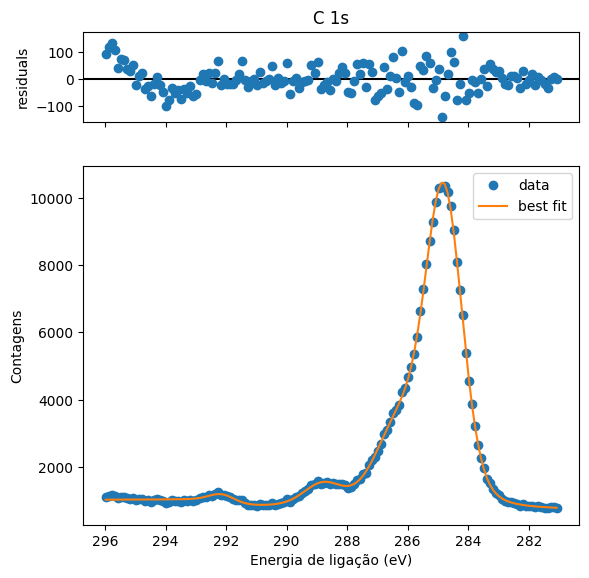

In [10]:
resultado_c1s.plot(title="C 1s", xlabel="Energia de ligação (eV)", ylabel="Contagens")
plt.gca().invert_xaxis();

### Componentes do ajuste

C–C / C–H    centro = 284.80 eV   FWHM = 1.45 eV   área = 71 %
C–O          centro = 286.24 eV   FWHM = 1.89 eV   área = 23 %
O–C=O        centro = 288.80 eV   FWHM = 1.49 eV   área = 5 %
CF₂          centro = 292.13 eV   FWHM = 1.04 eV   área = 1 %


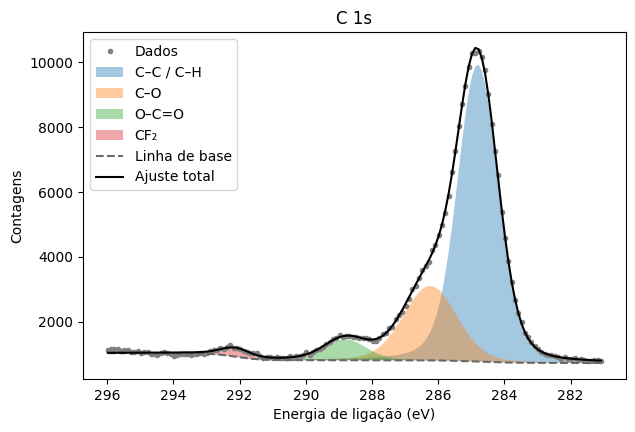

In [11]:
NOMES_C1S = ["C–C / C–H", "C–O", "O–C=O", "CF₂"]

fig, eixo = plt.subplots(figsize=(7, 4.5))
plota_componentes(df_c1s, resultado_c1s, NOMES_C1S, "C 1s", eixo)

mostra_porcentagens(resultado_c1s, NOMES_C1S)

## O 1s

1 pico: Si–O da sílica. Um segundo pico foi testado, mas a posição dele mudava conforme o modelo, então não é confiável.

### Carregando e cortando os dados

Mesma lógica do notebook (`logic = df["eV"] <= 535`), mas cortando dos dois lados: ficamos só com a região entre 527 e 540 eV.

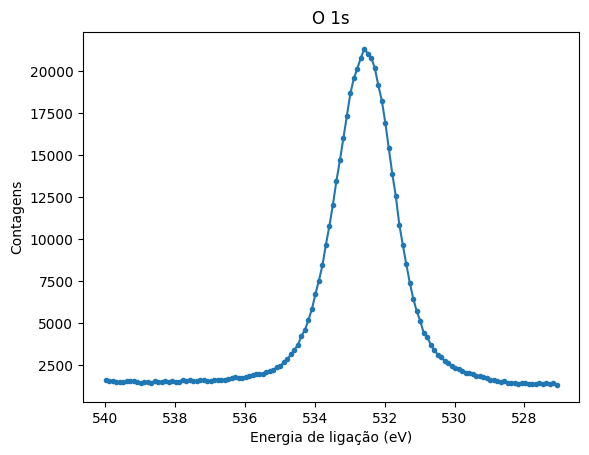

In [12]:
df_o1s = le_arquivo_avg(ARQUIVO_O1S)

logic = (df_o1s["eV"] >= 527) & (df_o1s["eV"] <= 540)
df_o1s = df_o1s.loc[logic]

eixo = df_o1s.plot("eV", "Contagens", marker="o", markersize=3, legend=False)
eixo.invert_xaxis()
eixo.set(xlabel="Energia de ligação (eV)", ylabel="Contagens", title="O 1s");

### Palpites, modelo e ajuste

- `PALPITES_...`: um item por pico, no formato `(centro, mínimo, máximo, área)`.
- `monta_modelo(...)`: monta o modelo composto e os parâmetros (função lá de cima).
- `.fit(...)` e `fit_report()`: iguais ao notebook, com um argumento a mais: `method="least_squares"`. É outro algoritmo de ajuste do lmfit, que lida melhor com os limites `min`/`max`. Com o algoritmo padrão, quando uma sigmoide encosta no limite zero, o lmfit não consegue calcular as incertezas (os `+/-` do relatório).
- `resultado_fit.plot(...)`: gráfico pronto do lmfit, com os resíduos em cima e o ajuste embaixo. O `title` evita que ele use como título o nome enorme do modelo. `plt.gca()` pega o último gráfico desenhado para inverter o eixo x (o de resíduos acompanha).

In [13]:
PALPITES_O1S = [
    (532.6, 531.9, 533.2, 48000),  # Si–O (SiO2)
]

modelo_o1s, params_o1s = monta_modelo(PALPITES_O1S, palpite_constante=1200)

dados_x = df_o1s["eV"].values
dados_y = df_o1s["Contagens"].values

resultado_o1s = modelo_o1s.fit(dados_y, params_o1s, x=dados_x, method="least_squares")

print(resultado_o1s.fit_report())

[[Model]]
    ((Model(constant, prefix='const_') + Model(voigt, prefix='p1_')) + Model(step, prefix='sigmoid1_', form='logistic'))
[[Fit Statistics]]
    # fitting method   = least_squares
    # function evals   = 63
    # data points      = 130
    # variables        = 6
    chi-square         = 1422953.25
    reduced chi-square = 11475.4295
    Akaike info crit   = 1221.09237
    Bayesian info crit = 1238.29758
    R-squared          = 0.99966492
[[Variables]]
    const_c:             1160.64322 +/- 26.2383148 (2.26%) (init = 1200)
    p1_amplitude:        48331.3356 +/- 290.558845 (0.60%) (init = 48000)
    p1_center:           532.560216 +/- 0.00188363 (0.00%) (init = 532.6)
    p1_sigma:            0.64469759 +/- 0.00765428 (1.19%) (init = 0.5)
    p1_gamma:            0.37051351 +/- 0.01201648 (3.24%) (init = 0.2)
    p1_fwhm:             1.95296712 +/- 0.00532022 (0.27%) == '1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)'
    p1_height:           19949.3136 +/- 46

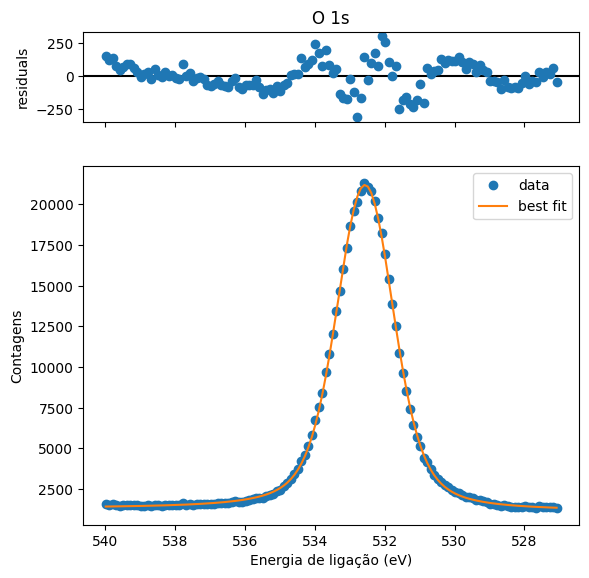

In [14]:
resultado_o1s.plot(title="O 1s", xlabel="Energia de ligação (eV)", ylabel="Contagens")
plt.gca().invert_xaxis();

### Componentes do ajuste

Si–O (SiO₂)  centro = 532.56 eV   FWHM = 1.95 eV   área = 100 %


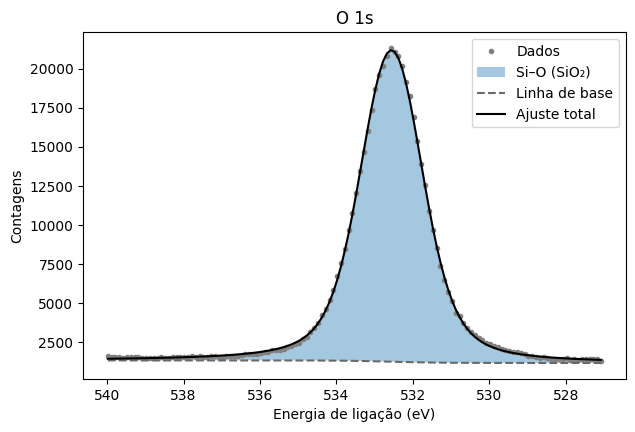

In [15]:
NOMES_O1S = ["Si–O (SiO₂)"]

fig, eixo = plt.subplots(figsize=(7, 4.5))
plota_componentes(df_o1s, resultado_o1s, NOMES_O1S, "O 1s", eixo)

mostra_porcentagens(resultado_o1s, NOMES_O1S)

## Si 2p

1 pico: Si⁴⁺ da sílica. Em teoria o Si 2p tem dois componentes, mas em compostos de silício essa separação pode ser ignorada.

### Carregando e cortando os dados

Mesma lógica do notebook (`logic = df["eV"] <= 535`), mas cortando dos dois lados: ficamos só com a região entre 98 e 108 eV.

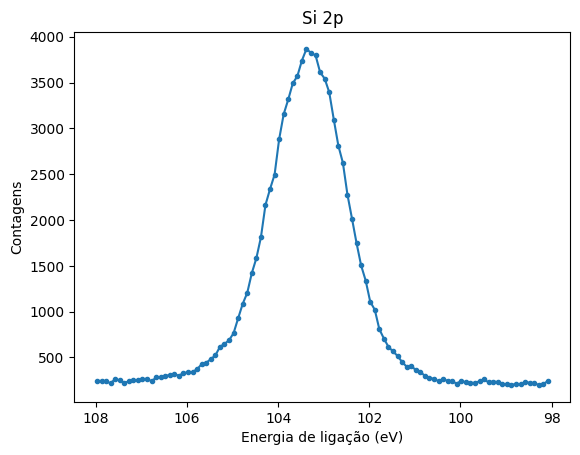

In [16]:
df_si2p = le_arquivo_avg(ARQUIVO_SI2P)

logic = (df_si2p["eV"] >= 98) & (df_si2p["eV"] <= 108)
df_si2p = df_si2p.loc[logic]

eixo = df_si2p.plot("eV", "Contagens", marker="o", markersize=3, legend=False)
eixo.invert_xaxis()
eixo.set(xlabel="Energia de ligação (eV)", ylabel="Contagens", title="Si 2p");

### Palpites, modelo e ajuste

- `PALPITES_...`: um item por pico, no formato `(centro, mínimo, máximo, área)`.
- `monta_modelo(...)`: monta o modelo composto e os parâmetros (função lá de cima).
- `.fit(...)` e `fit_report()`: iguais ao notebook, com um argumento a mais: `method="least_squares"`. É outro algoritmo de ajuste do lmfit, que lida melhor com os limites `min`/`max`. Com o algoritmo padrão, quando uma sigmoide encosta no limite zero, o lmfit não consegue calcular as incertezas (os `+/-` do relatório).
- `resultado_fit.plot(...)`: gráfico pronto do lmfit, com os resíduos em cima e o ajuste embaixo. O `title` evita que ele use como título o nome enorme do modelo. `plt.gca()` pega o último gráfico desenhado para inverter o eixo x (o de resíduos acompanha).

In [17]:
PALPITES_SI2P = [
    (103.3, 102.8, 103.9, 8000),   # Si4+ (SiO2)
]

modelo_si2p, params_si2p = monta_modelo(PALPITES_SI2P, palpite_constante=200)

dados_x = df_si2p["eV"].values
dados_y = df_si2p["Contagens"].values

resultado_si2p = modelo_si2p.fit(dados_y, params_si2p, x=dados_x, method="least_squares")

print(resultado_si2p.fit_report())

[[Model]]
    ((Model(constant, prefix='const_') + Model(voigt, prefix='p1_')) + Model(step, prefix='sigmoid1_', form='logistic'))
[[Fit Statistics]]
    # fitting method   = least_squares
    # function evals   = 56
    # data points      = 100
    # variables        = 6
    chi-square         = 99515.4921
    reduced chi-square = 1058.67545
    Akaike info crit   = 702.289842
    Bayesian info crit = 717.920864
    R-squared          = 0.99923470
[[Variables]]
    const_c:             174.613276 +/- 9.09942492 (5.21%) (init = 200)
    p1_amplitude:        8240.59260 +/- 108.347384 (1.31%) (init = 8000)
    p1_center:           103.334129 +/- 0.00309244 (0.00%) (init = 103.3)
    p1_sigma:            0.70552857 +/- 0.01356304 (1.92%) (init = 0.5)
    p1_gamma:            0.23460479 +/- 0.02449647 (10.44%) (init = 0.2)
    p1_fwhm:             1.92650804 +/- 0.00821915 (0.43%) == '1.0692*p1_gamma+sqrt(0.8664*p1_gamma**2+5.545083*p1_sigma**2)'
    p1_height:           3641.65628 +/- 15.

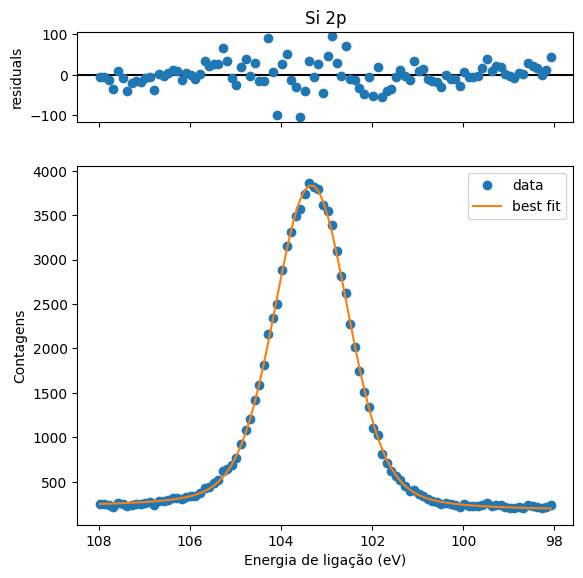

In [18]:
resultado_si2p.plot(title="Si 2p", xlabel="Energia de ligação (eV)", ylabel="Contagens")
plt.gca().invert_xaxis();

### Componentes do ajuste

Si⁴⁺ (SiO₂)  centro = 103.33 eV   FWHM = 1.93 eV   área = 100 %


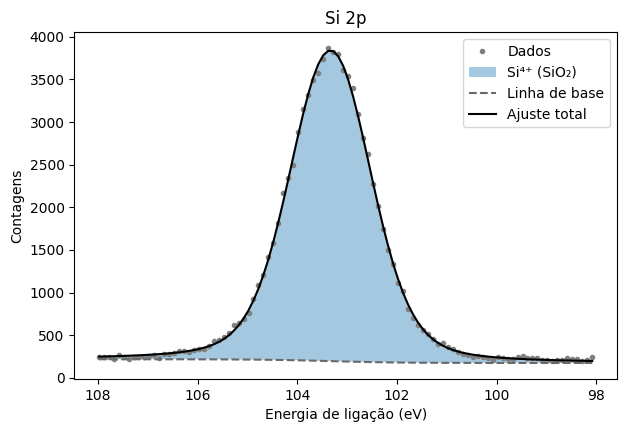

In [19]:
NOMES_SI2P = ["Si⁴⁺ (SiO₂)"]

fig, eixo = plt.subplots(figsize=(7, 4.5))
plota_componentes(df_si2p, resultado_si2p, NOMES_SI2P, "Si 2p", eixo)

mostra_porcentagens(resultado_si2p, NOMES_SI2P)

## Figura final com os 4 painéis

- `plt.subplots(2, 2, ...)`: cria uma figura com 2 linhas e 2 colunas de gráficos. `eixos[0, 0]` é o de cima à esquerda, `eixos[1, 1]` o de baixo à direita.
- Reaproveitamos as mesmas funções, mudando só o `eixo` onde cada gráfico é desenhado.
- `tight_layout()`: ajusta os espaços para nada ficar sobreposto.
- `savefig(...)`: salva a figura em um arquivo PNG. `dpi=300` deixa a imagem com boa resolução para o relatório.

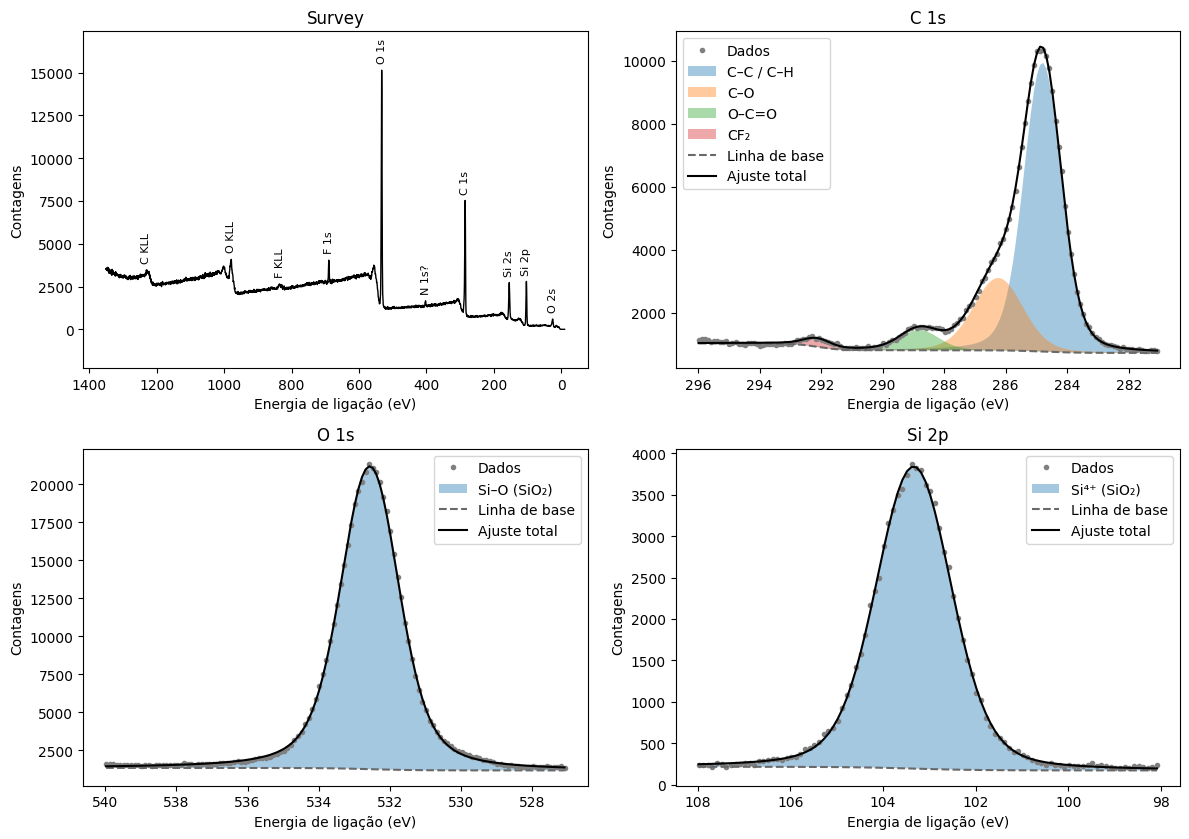

In [20]:
figura, eixos = plt.subplots(2, 2, figsize=(12, 8.5))

# survey
eixo = eixos[0, 0]
eixo.plot(df_survey["eV"], df_survey["Contagens"], color="black", lw=1)
for nome, energia in IDENTIFICACAO.items():
    i = np.argmin(np.abs(df_survey["eV"].values - energia))
    eixo.annotate(
        nome,
        (df_survey["eV"].values[i], df_survey["Contagens"].values[i]),
        xytext=(0, 5), textcoords="offset points",
        rotation=90, ha="center", va="bottom", fontsize=8,
    )
eixo.margins(y=0.15)
eixo.invert_xaxis()
eixo.set(xlabel="Energia de ligação (eV)", ylabel="Contagens", title="Survey")

# regiões de alta resolução
plota_componentes(df_c1s, resultado_c1s, NOMES_C1S, "C 1s", eixos[0, 1])
plota_componentes(df_o1s, resultado_o1s, NOMES_O1S, "O 1s", eixos[1, 0])
plota_componentes(df_si2p, resultado_si2p, NOMES_SI2P, "Si 2p", eixos[1, 1])

figura.tight_layout()
figura.savefig("xps_figura.png", dpi=300)

**Lembrete para o relatório:** a linha de base usada aqui é constante + sigmoides (a receita do notebook da aula). Em XPS, o mais comum na literatura é a linha de base de Shirley. Por isso, descreva o método na legenda da figura, como o próprio notebook recomenda.